<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkST0151ENSkillsNetwork20531532-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>



# **Final Project: Boston Housing**


##### Estimated time needed: **60** minutes


#### Import the required libraries we need for the lab.


In [1]:
import piplite
await piplite.install(['numpy'],['pandas'])
await piplite.install(['seaborn'])

In [4]:
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [5]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [6]:
boston_df=pd.read_csv(boston_url)

#### Add your code below following the instructions given in the course to complete the peer graded assignment


Task 1: Familiarize Yourself with the Dataset
Display the first 5 rows of the dataset.

Display the data types of each column.

Check for missing values in each column.

Check for duplicate rows.

Display the correlation matrix of the dataset.

Ось детальний розбір кожного стовпця (змінної) у класичному датасеті Boston Housing:
Unnamed: 0 — Технічний стовпець індексів (порядковий номер рядка від 0 до 505), який часто з'являється при завантаженні CSV-файлу,
         якщо в оригіналі не було явно вказаного стовпця ідентифікаторів.
CRIM — Рівень злочинності на душу населення в районі.
ZN — Частка житлової землі, виділеної під великі ділянки (понад 25 000 кв. футів). Показує, наскільки район просторий і менш щільно забудований.
INDUS — Частка неторгових (промислових/виробничих) площ у районі.
CHAS — Бінарна (фіктивна) змінна річки Чарльз: приймає значення 1, якщо район межує з річкою, і 0, якщо ні.
NOX — Концентрація оксидів азоту (показник забруднення повітря).
RM — Середня кількість кімнат в одному житловому будинку.
AGE — Частка старих будівель (відсоток будинків у власності, побудованих до 1940 року).
DIS — Зважена відстань до п'яти головних ділових/робочих центрів Бостона.
RAD — Індекс доступності радіальних швидкісних магістралей (шосе).
TAX — Повна ставка податку на нерухомість за кожні $10 000 вартості.
PTRATIO — Співвідношення кількості учнів до кількості вчителів у школах району (індикатор якості освітньої сфери).
LSTАT — Відсоток населення району з нижчим соціально-економічним статусом.
MEDV — Цільова змінна: Медіанна вартість житла, що перебуває у власності, у тисячах доларів США. Зазвичай саме цей показник прогнозують за допомогою моделей регресії.

In [9]:
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [10]:
boston_df.dtypes

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object

In [11]:
boston_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  506 non-null    int64  
 1   CRIM        506 non-null    float64
 2   ZN          506 non-null    float64
 3   INDUS       506 non-null    float64
 4   CHAS        506 non-null    float64
 5   NOX         506 non-null    float64
 6   RM          506 non-null    float64
 7   AGE         506 non-null    float64
 8   DIS         506 non-null    float64
 9   RAD         506 non-null    float64
 10  TAX         506 non-null    float64
 11  PTRATIO     506 non-null    float64
 12  LSTAT       506 non-null    float64
 13  MEDV        506 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 55.4 KB


In [12]:
boston_df.isnull().sum()

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64

In [13]:
boston_df.duplicated().sum()

0

In [14]:
boston_df.corr()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
Unnamed: 0,1.000000,0.407407,-0.103393,0.399439,-0.003759,0.398736,-0.079971,0.203784,-0.302211,0.686002,0.666626,0.291074,0.258465,-0.226604
CRIM,0.407407,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.103393,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.399439,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.003759,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.398736,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.079971,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.203784,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.302211,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.686002,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626


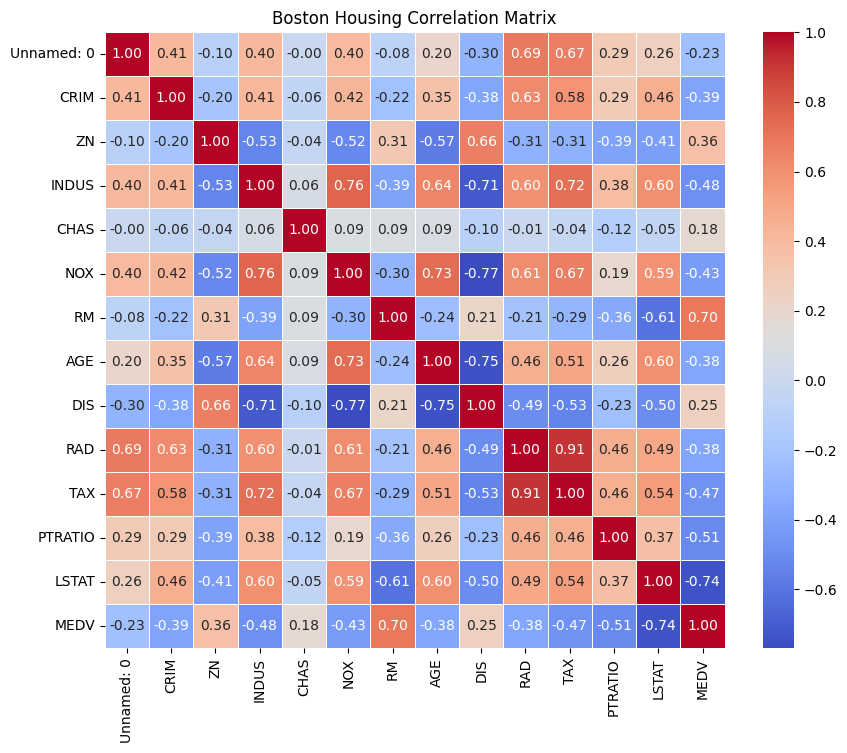

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(boston_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Boston Housing Correlation Matrix')
plt.show()

Task 2: Generate Descriptive Statistics and Visualizations
Display descriptive statistics of the dataset.

Create a boxplot for MEDV (Median value of owner-occupied homes).

Create a bar plot for CHAS (Charles River dummy variable).

Discretize AGE into three groups and create a boxplot of MEDV versus these groups:

Create a scatter plot showing the relationship between NOX (nitric oxide concentrations) and INDUS (non-retail business acres).

Create a histogram for PTRATIO (pupil-teacher ratio).

In [17]:
boston_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


In [18]:
boston_df.describe(include='all')

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


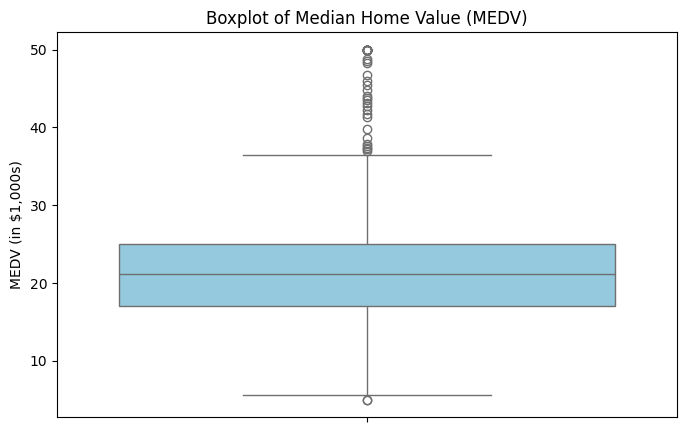

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(y=boston_df['MEDV'], color='skyblue')
plt.title('Boxplot of Median Home Value (MEDV)')
plt.ylabel('MEDV (in $1,000s)')
plt.show()

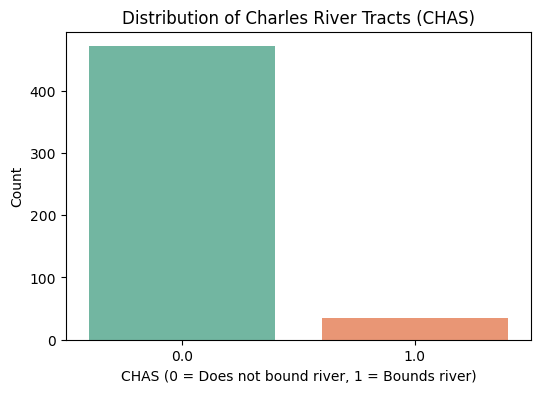

In [21]:
plt.figure(figsize=(6, 4))
sns.countplot(x='CHAS', data=boston_df, hue='CHAS', palette='Set2', legend=False)
plt.title('Distribution of Charles River Tracts (CHAS)')
plt.xlabel('CHAS (0 = Does not bound river, 1 = Bounds river)')
plt.ylabel('Count')
plt.show()

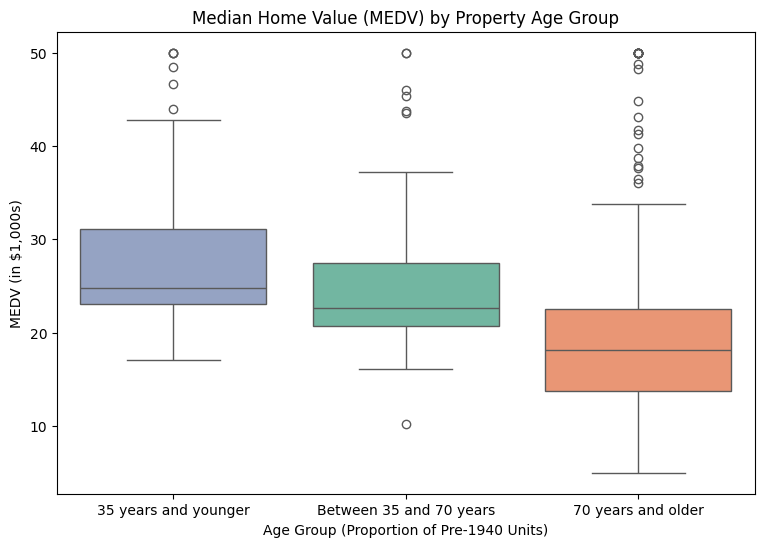

In [22]:
# 1. Discretize the AGE column into three categorical groups
boston_df.loc[(boston_df['AGE'] <= 35), 'AGE_GROUP'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'AGE_GROUP'] = 'Between 35 and 70 years'
boston_df.loc[(boston_df['AGE'] >= 70), 'AGE_GROUP'] = '70 years and older'

# Define the order so the boxplot displays chronologically
age_order = ['35 years and younger', 'Between 35 and 70 years', '70 years and older']

# 2. Create the boxplot of MEDV vs AGE_GROUP
plt.figure(figsize=(9, 6))
sns.boxplot(
    x='AGE_GROUP', 
    y='MEDV', 
    data=boston_df, 
    order=age_order, 
    hue='AGE_GROUP', 
    palette='Set2', 
    legend=False
)
plt.title('Median Home Value (MEDV) by Property Age Group')
plt.xlabel('Age Group (Proportion of Pre-1940 Units)')
plt.ylabel('MEDV (in $1,000s)')
plt.show()

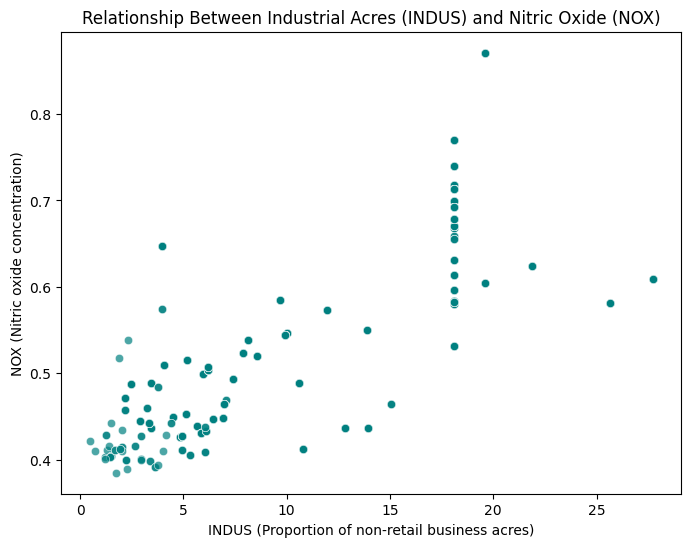

In [23]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df, alpha=0.7, color='teal')
plt.title('Relationship Between Industrial Acres (INDUS) and Nitric Oxide (NOX)')
plt.xlabel('INDUS (Proportion of non-retail business acres)')
plt.ylabel('NOX (Nitric oxide concentration)')
plt.show()

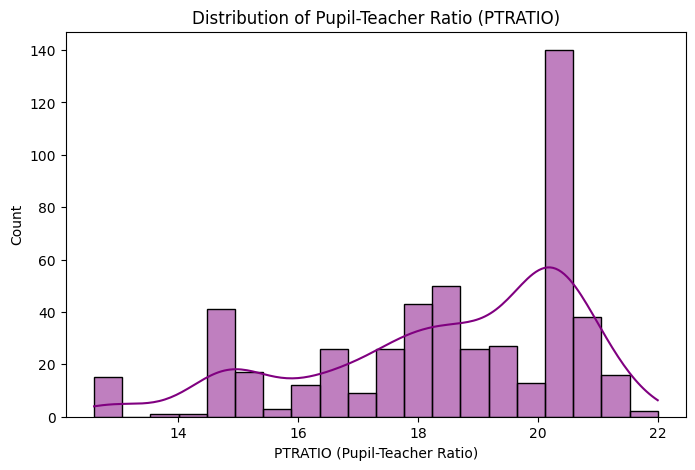

In [24]:
plt.figure(figsize=(8, 5))
sns.histplot(boston_df['PTRATIO'], bins=20, kde=True, color='purple')
plt.title('Distribution of Pupil-Teacher Ratio (PTRATIO)')
plt.xlabel('PTRATIO (Pupil-Teacher Ratio)')
plt.ylabel('Count')
plt.show()

Task 3: Apply Statistical Tests
Use Levene’s test to check if the variances of MEDV for homes bounded by the Charles River (CHAS = 1) and those not bounded (CHAS = 0) are equal.

Perform a T-test to determine if there is a significant difference in MEDV between homes bounded and not bounded by the Charles River.

Conduct an ANOVA test to compare MEDV among the three AGE groups created earlier.

Perform a Pearson correlation test to assess the relationship between NOX and INDUS.

Fit a simple linear regression model to evaluate the impact of DIS (distance to employment centres) on MEDV. Report and interpret the regression results.

In [26]:
import scipy.stats as stats
# Split MEDV into two groups based on CHAS
chas_0 = boston_df[boston_df['CHAS'] == 0]['MEDV']
chas_1 = boston_df[boston_df['CHAS'] == 1]['MEDV']

# Perform Levene's test (using center='mean' or default center='median')
stat, p_value = stats.levene(chas_0, chas_1, center='mean')

print(f"Levene's Test Statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

Levene's Test Statistic: 8.7519
P-value: 0.0032


In [27]:
# Split MEDV into two groups based on CHAS
chas_0 = boston_df[boston_df['CHAS'] == 0]['MEDV']
chas_1 = boston_df[boston_df['CHAS'] == 1]['MEDV']

# Perform Welch's two-sample t-test (equal_var=False)
t_stat, p_value = stats.ttest_ind(chas_0, chas_1, equal_var=False)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

T-statistic: -3.1133
P-value: 0.0036


Since the p-value (0.0036) is less than the significance level $\alpha = 0.05$, we reject the null hypothesis ($H_0$).
Conclusion:There is a statistically significant difference in the mean MEDV (median home value) between tracts bounded 
by the Charles River (CHAS = 1) and those not bounded by the river (CHAS = 0).
Because the t-statistic is negative (-3.1133 when subtracting group 1 from group 0), 
homes bordering the Charles River have a significantly higher average value than homes that do not border the river.

In [28]:
# Extract MEDV values for each of the three AGE groups
thirtyfive_lower = boston_df[boston_df['AGE_GROUP'] == '35 years and younger']['MEDV']
thirtyfive_seventy = boston_df[boston_df['AGE_GROUP'] == 'Between 35 and 70 years']['MEDV']
seventy_older = boston_df[boston_df['AGE_GROUP'] == '70 years and older']['MEDV']

# Perform one-way ANOVA
f_stat, p_value = stats.f_oneway(thirtyfive_lower, thirtyfive_seventy, seventy_older)

print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.4e}")  # Using scientific notation as p-value is very small

F-statistic: 36.4076
P-value: 1.7105e-15


Since the p-value ($1.7105 \times 10^{-15}$) is far below the significance level $\alpha = 0.05$, we reject the null hypothesis ($H_0$).

Conclusion:
There is a statistically significant difference in the mean MEDV (median home value) 
among at least two of the three property age groups (35 years and younger, Between 35 and 70 years, and 70 years and older).

Combined with your earlier boxplot, this confirms that the age profile of a neighborhood has a significant impact on median 
property values, with newer tracts generally commanding higher values than older tracts.

In [29]:
# Perform Pearson correlation test
corr_coef, p_value = stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])

print(f"Pearson Correlation Coefficient (r): {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")

Pearson Correlation Coefficient (r): 0.7637
P-value: 7.9134e-98


Since the p-value ($7.9134 \times 10^{-98}$) is virtually zero and far below $\alpha = 0.05$, we decisively reject the null hypothesis ($H_0$).
Conclusion:
Strong Positive Correlation ($r = 0.7637$): There is a strong, direct linear relationship between industrial land use (INDUS) and nitric oxide concentration (NOX).
Statistical Significance: The extremely small $p$-value confirms that this relationship is highly significant and not the result of random chance.
Practical Interpretation: Districts with a higher concentration of non-retail and industrial business acreage consistently suffer from significantly higher air pollution (higher NOX levels), quantifying a major environmental impact of local industrial zoning in the dataset.

In [30]:
X = boston_df['DIS']
y = boston_df['MEDV']

# Add an intercept (constant) term to the model
X = sm.add_constant(X)

# Fit the Ordinary Least Squares (OLS) regression model
model = sm.OLS(y, X).fit()

# Print the full regression summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        14:50:13   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

Detailed Breakdown of Your Output:Goodness of Fit (R-squared = 0.062): Distance to employment centers explains 6.2% of the variance in median home values (Adj. R-squared = 0.061). While meaningful, 93.8% of the price variation comes from other variables.Overall Model Significance (F-statistic = 33.58, Prob (F-statistic) = 1.21e-08): Because the F-test $p$-value ($1.21 \times 10^{-8}$) is far below $\alpha = 0.05$, the regression model as a whole is statistically significant.Slope Coefficient (DIS = 1.0916, t = 5.795, P>|t| = 0.000):For every 1-unit increase in weighted distance to Boston employment centers, median home value increases by $1,091.60 on average.The 95% confidence interval ([0.722, 1.462]) does not contain zero, confirming a reliably positive relationship.Intercept (const = 18.3901): At a theoretical distance of DIS = 0, the baseline predicted median home value is $18,390.Residual Diagnostics (Omnibus = 139.779, Jarque-Bera = 305.104, Durbin-Watson = 0.570):The high Omnibus/JB statistics ($p \text{ less than } 0.001$) and positive skewness (1.466) indicate that the residuals are not normally distributed—largely driven by the right-skewed high-value homes capped at $50,000.The low Durbin-Watson value (0.570, well below 2.0) points to positive autocorrelation across ordered observations, reflecting geographic clustering in how the census tracts are ordered in the dataset.In practical terms, homes situated further out in suburban areas away from central employment hubs tend to command modestly higher prices, though distance alone is a weak standalone predictor compared to structural features like room count (RM) or neighborhood socioeconomic status (LSTAT).